# PolyNex: tables + YOLOv11s / YOLOv12s / YOLO26s training (50 epochs)

**Before you run:**
1. Right panel -> Input: the **PolyNex** dataset (PolyNex.v3) must be attached
2. Settings -> **Accelerator = GPU T4 x2** (or P100)
3. Settings -> **Internet = ON** (needed to install ultralytics and download the pretrained weights)

Then **Save Version -> Save & Run All (Commit)** so it keeps running even if you close the browser.
Everything ends in `/kaggle/working/PolyNex_results.zip`.

In [1]:
# 1) Setup
!pip install -q -U ultralytics
import os, warnings
warnings.filterwarnings('ignore')
import torch, ultralytics
from ultralytics import settings
settings.update({'wandb': False})
print('ultralytics', ultralytics.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU - turn on the accelerator!')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.216
GPU: Tesla T4


In [2]:
# 2) Config + load the dataset you uploaded to Kaggle (no Roboflow download)
from pathlib import Path
import yaml, glob

# ---------- the only things you may want to change ----------
DATASET_ROOT = '/kaggle/input/datasets/akashroy007/polynex/PolyNex.v3'
EPOCHS = 50
IMGSZ = 640
BATCH = 16
SEED = 42
# ------------------------------------------------------------

TRAIN_ROOT = Path(DATASET_ROOT)
if not (TRAIN_ROOT / 'data.yaml').exists():
    found = sorted(glob.glob('/kaggle/input/**/data.yaml', recursive=True))
    print('Path above not found. data.yaml files found:', found)
    TRAIN_ROOT = Path(found[0]).parent
STATS_ROOT = TRAIN_ROOT
print('Using dataset:', TRAIN_ROOT)

WORK = Path('/kaggle/working')

# make the two lowercase class names match the paper
RENAME = {'aluminium_waste': 'Aluminium Waste', 'electrical_waste': 'Electrical Waste'}

def fix_yaml(root):
    cfg = yaml.safe_load(open(root / 'data.yaml'))
    names = cfg['names']
    names = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
    names = [RENAME.get(n, n) for n in names]
    val_dir = 'valid' if (root / 'valid').exists() else 'val'
    new = {'path': str(root), 'train': 'train/images', 'val': f'{val_dir}/images',
           'test': 'test/images', 'nc': len(names), 'names': names}
    out = WORK / 'data_fixed.yaml'   # /kaggle/input is read-only, so the yaml lives in /kaggle/working
    yaml.safe_dump(new, open(out, 'w'), sort_keys=False)
    return out, names, val_dir

DATA_YAML, CLASS_NAMES, STATS_VAL_DIR = fix_yaml(TRAIN_ROOT)
print('Classes:', CLASS_NAMES)
for s in ['train', STATS_VAL_DIR, 'test']:
    d = TRAIN_ROOT / s / 'images'
    print(s, len(list(d.glob('*'))) if d.exists() else 'missing', 'images')

Using dataset: /kaggle/input/datasets/akashroy007/polynex/PolyNex.v3
Classes: ['Construction Waste', 'Food and Organic Waste', 'Metal Scrap Waste', 'Plastic Waste', 'Polythene Waste', 'Aluminium Waste', 'Electrical Waste']
train 6549 images
valid 631 images
test 315 images


## Table 3: split statistics with multi-object image percentage
Counts one copy per original photo (augmented training copies are dropped), so the numbers refer to the *original* images, as in the paper.

In [3]:
# 3) Table 3 + metadata.csv (Table 7)
import pandas as pd, numpy as np
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def base(stem):
    return stem.split('.rf.')[0]

def read_split(root, folder, tname, mname, names):
    imgs, anns, seen = [], [], set()
    for p in sorted((root / folder / 'images').iterdir()):
        if p.suffix.lower() not in IMG_EXT:
            continue
        b = base(p.stem)
        if b in seen:
            continue
        seen.add(b)
        lf = root / folder / 'labels' / (p.stem + '.txt')
        rows = [l.split() for l in lf.read_text().splitlines() if l.strip()] if lf.exists() else []
        imgs.append({'Image': p.name, 'Split': tname, 'n': len(rows)})
        for r in rows:
            cid = int(float(r[0]))
            anns.append({'Image': p.name, 'Set': mname, 'Class ID': cid, 'Class Name': names[cid],
                         'X': float(r[1]), 'Y': float(r[2]), 'Width': float(r[3]), 'Height': float(r[4])})
    return imgs, anns

FOLDERS = [('train', 'Train', 'Train'), (STATS_VAL_DIR, 'Validation', 'Valid'), ('test', 'Test', 'Test')]
img_rows, ann_rows = [], []
for folder, tname, mname in FOLDERS:
    i, a = read_split(STATS_ROOT, folder, tname, mname, CLASS_NAMES)
    img_rows += i
    ann_rows += a
imgs_df, ann_df = pd.DataFrame(img_rows), pd.DataFrame(ann_rows)

rows = []
for _, tname, _m in FOLDERS:
    d = imgs_df[imgs_df.Split == tname]
    rows.append([tname, len(d), int(d.n.sum()), int((d.n > 1).sum())])
tab = pd.DataFrame(rows, columns=['Split', 'Images', 'Annotations', 'Multi'])
tot = tab[['Images', 'Annotations', 'Multi']].sum()

def pct(a, b):
    return f'{int(a):,} ({100 * a / b:.1f}%)'

table3 = pd.DataFrame({
    'Split': list(tab.Split) + ['Total'],
    'Images (%)': [pct(r.Images, tot.Images) for r in tab.itertuples()] + [f'{int(tot.Images):,} (100%)'],
    'Annotations (%)': [pct(r.Annotations, tot.Annotations) for r in tab.itertuples()] + [f'{int(tot.Annotations):,} (100%)'],
    'Avg. Ann./Image': [f'{r.Annotations / r.Images:.2f}' for r in tab.itertuples()] + [f'{tot.Annotations / tot.Images:.2f}'],
    'Multi-object Images (%)': [pct(r.Multi, r.Images) for r in tab.itertuples()] + [pct(tot.Multi, tot.Images)],
})
table3.to_csv(WORK / 'table3_split_stats.csv', index=False)
display(table3)

m = [100 * r.Multi / r.Images for r in tab.itertuples()]
print(f'Images containing more than one annotated object account for {m[0]:.1f}%, {m[1]:.1f}%, and {m[2]:.1f}% of the training, validation, and test subsets, respectively.')

# sanity check against the numbers printed in the paper
paper = {'Train': (2208, 2834), 'Validation': (631, 791), 'Test': (315, 397)}
for r in tab.itertuples():
    pi, pa = paper[r.Split]
    flag = 'OK' if (r.Images, r.Annotations) == (pi, pa) else 'DIFFERENT from paper'
    print(f'{r.Split}: images {r.Images} (paper {pi}), annotations {r.Annotations} (paper {pa}) -> {flag}')

# ---- metadata.csv (all annotations) ----
meta = ann_df[['Image', 'Set', 'Class ID', 'Class Name', 'X', 'Y', 'Width', 'Height']].copy()
meta[['X', 'Y', 'Width', 'Height']] = meta[['X', 'Y', 'Width', 'Height']].round(6)
meta.to_csv(WORK / 'metadata.csv', index=False)
print('metadata.csv rows:', len(meta))

# Table 7 style sample: first image that has more than one object
sample_img = imgs_df[imgs_df.n > 1].iloc[0].Image
table7 = meta[meta.Image == sample_img]
table7.to_csv(WORK / 'metadata_table7_sample.csv', index=False)
display(table7)

# class distribution per split (like Table 5)
dist = pd.crosstab(meta['Class Name'], meta['Set'])[['Train', 'Valid', 'Test']]
dist['Total'] = dist.sum(axis=1)
dist.loc['Total'] = dist.sum()
dist.to_csv(WORK / 'class_distribution.csv')
display(dist)

,Split,Images (%),Annotations (%),Avg. Ann./Image,Multi-object Images (%)
0,Train,"2,208 (70.0%)","2,821 (70.4%)",1.28,341 (15.4%)
1,Validation,631 (20.0%),788 (19.7%),1.25,95 (15.1%)
2,Test,315 (10.0%),396 (9.9%),1.26,44 (14.0%)
3,Total,"3,154 (100%)","4,005 (100%)",1.27,480 (15.2%)


Images containing more than one annotated object account for 15.4%, 15.1%, and 14.0% of the training, validation, and test subsets, respectively.
Train: images 2208 (paper 2208), annotations 2821 (paper 2834) -> DIFFERENT from paper
Validation: images 631 (paper 631), annotations 788 (paper 791) -> DIFFERENT from paper
Test: images 315 (paper 315), annotations 396 (paper 397) -> DIFFERENT from paper
metadata.csv rows: 4005


,Image,Set,Class ID,Class Name,X,Y,Width,Height
11,0b7282bc-aluminium_waste_41_jpg.rf.a02ff196aca...,Train,5,Aluminium Waste,0.254688,0.516406,0.229688,0.242188
12,0b7282bc-aluminium_waste_41_jpg.rf.a02ff196aca...,Train,5,Aluminium Waste,0.446094,0.685938,0.339062,0.134375
13,0b7282bc-aluminium_waste_41_jpg.rf.a02ff196aca...,Train,5,Aluminium Waste,0.701562,0.530469,0.134375,0.287500
14,0b7282bc-aluminium_waste_41_jpg.rf.a02ff196aca...,Train,5,Aluminium Waste,0.464062,0.557812,0.179688,0.165625
15,0b7282bc-aluminium_waste_41_jpg.rf.a02ff196aca...,Train,5,Aluminium Waste,0.701562,0.530469,0.134375,0.287500
16,0b7282bc-aluminium_waste_41_jpg.rf.a02ff196aca...,Train,5,Aluminium Waste,0.590625,0.574219,0.134375,0.276562
17,0b7282bc-aluminium_waste_41_jpg.rf.a02ff196aca...,Train,5,Aluminium Waste,0.585665,0.273519,0.322513,0.369432


Set,Train,Valid,Test,Total
Class Name,,,,
Aluminium Waste,383,91,41,515
Construction Waste,212,63,28,303
Electrical Waste,300,82,34,416
Food and Organic Waste,714,192,118,1024
Metal Scrap Waste,482,140,66,688
Plastic Waste,341,102,54,497
Polythene Waste,389,118,55,562
Total,2821,788,396,4005


In [4]:
# 3b) Table 7 in the same layout as the paper (Field/Value on top, one row per object) + ready LaTeX code
two = imgs_df[imgs_df.n == 2]
sample_img = (two if len(two) else imgs_df[imgs_df.n > 1]).iloc[0].Image
t7 = meta[meta.Image == sample_img].reset_index(drop=True)
objs = t7[['Class ID', 'Class Name', 'X', 'Y', 'Width', 'Height']]

print('Field  Image ->', sample_img)
print('Field  Set   ->', t7.loc[0, 'Set'])
display(objs)
objs.to_csv(WORK / 'table7_sample_objects.csv', index=False)

def esc(s):
    return str(s).replace('_', r'\_')

L = [r'\begin{table}[ht]', r'\centering', r'\begin{tabular}{|c|l|c|c|c|c|}', r'\hline',
     r'\textbf{Field} & \multicolumn{5}{l|}{\textbf{Value}} \\ \hline',
     r'Image & \multicolumn{5}{l|}{\texttt{\footnotesize ' + esc(sample_img) + r'}} \\ \hline',
     r'Set & \multicolumn{5}{l|}{' + str(t7.loc[0, 'Set']) + r'} \\ \hline',
     r'\textbf{Class ID} & \textbf{Class Name} & \textbf{X} & \textbf{Y} & \textbf{Width} & \textbf{Height} \\ \hline']
for r in objs.itertuples(index=False):
    L.append(f'{r[0]} & {r[1]} & {r[2]:.4f} & {r[3]:.4f} & {r[4]:.4f} & {r[5]:.4f} \\\\ \\hline')
L += [r'\end{tabular}',
      r'\caption{Sample \texttt{metadata.csv} record showing image name, dataset split, object classes, and bounding-box coordinates.}',
      r'\end{table}']
open(WORK / 'table7_latex.tex', 'w').write(chr(10).join(L))
print(chr(10).join(L))

Field  Image -> 0df2753b-aluminium_waste_227_jpg.rf.1d9be2af43825e23ec950949ecbd4621.jpg
Field  Set   -> Train


,Class ID,Class Name,X,Y,Width,Height
0,5,Aluminium Waste,0.594531,0.703125,0.306250,0.345312
1,5,Aluminium Waste,0.522656,0.346094,0.484375,0.370312


\begin{table}[ht]
\centering
\begin{tabular}{|c|l|c|c|c|c|}
\hline
\textbf{Field} & \multicolumn{5}{l|}{\textbf{Value}} \\ \hline
Image & \multicolumn{5}{l|}{\texttt{\footnotesize 0df2753b-aluminium\_waste\_227\_jpg.rf.1d9be2af43825e23ec950949ecbd4621.jpg}} \\ \hline
Set & \multicolumn{5}{l|}{Train} \\ \hline
\textbf{Class ID} & \textbf{Class Name} & \textbf{X} & \textbf{Y} & \textbf{Width} & \textbf{Height} \\ \hline
5 & Aluminium Waste & 0.5945 & 0.7031 & 0.3063 & 0.3453 \\ \hline
5 & Aluminium Waste & 0.5227 & 0.3461 & 0.4844 & 0.3703 \\ \hline
\end{tabular}
\caption{Sample \texttt{metadata.csv} record showing image name, dataset split, object classes, and bounding-box coordinates.}
\end{table}


## Train YOLOv11s, YOLOv12s, YOLO26s (same settings, 50 epochs)
Roughly 1 to 2 hours per model on a T4. A finished model is skipped if you re-run the cell.

In [5]:
# 4) Training
from ultralytics import YOLO
import shutil, time

MODELS = {'YOLOv11s': 'yolo11s.pt', 'YOLOv12s': 'yolo12s.pt', 'YOLO26s': 'yolo26s.pt'}
RUNS = WORK / 'runs'

for key, weights in MODELS.items():
    if (RUNS / key / 'weights' / 'best.pt').exists():
        print('skip (already trained):', key)
        continue
    t0 = time.time()
    model = YOLO(weights)
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
                workers=2, device=0, project=str(RUNS), name=key, exist_ok=True, plots=True)
    print(key, 'finished in', round((time.time() - t0) / 60, 1), 'min')
    del model
    torch.cuda.empty_cache()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv11s, nbs=64, nms=None, opset=None, optimize=False, o

In [6]:
# 5) Evaluate best weights on validation and test sets (this also generates PR / F1 / P / R curves + confusion matrices)
results, class_rows = [], []
for key in MODELS:
    best = YOLO(str(RUNS / key / 'weights' / 'best.pt'))
    for split in ['val', 'test']:
        mt = best.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, plots=True,
                      project=str(RUNS), name=f'{key}_{split}', exist_ok=True, verbose=False)
        results.append({'Model': key, 'Split': split,
                        'Precision': float(mt.box.mp), 'Recall': float(mt.box.mr),
                        'F1': float(np.mean(mt.box.f1)), 'mAP50': float(mt.box.map50),
                        'mAP50-95': float(mt.box.map), 'Inference ms/img': float(mt.speed['inference'])})
        for i, c in enumerate(mt.box.ap_class_index):
            class_rows.append({'Model': key, 'Split': split, 'Class': mt.names[int(c)],
                               'Precision': float(mt.box.p[i]), 'Recall': float(mt.box.r[i]),
                               'F1': float(mt.box.f1[i]), 'mAP50': float(mt.box.ap50[i])})
    del best
    torch.cuda.empty_cache()

comp = pd.DataFrame(results).round(4)
comp.to_csv(WORK / 'model_comparison.csv', index=False)
pd.DataFrame(class_rows).round(4).to_csv(WORK / 'per_class_results.csv', index=False)
display(comp)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,509 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 123.1±39.7 MB/s, size: 68.7 KB)
val: Scanning /kaggle/input/datasets/akashroy007/polynex/PolyNex.v3/valid/labels... 631 images, 0 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 631/631 768.4it/s 0.8s
val: /kaggle/input/datasets/akashroy007/polynex/PolyNex.v3/valid/images/20261001_142023_heic.rf.333bc765bfcbfe501474e4e1f66f706a.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/input/datasets/akashroy007/polynex/PolyNex.v3/valid/images/20261001_145921_heic.rf.13e79ccb9b4ae7e17f711ece3159bbb6.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/input/datasets/akashroy007/polynex/PolyNex.v3/valid/images/2e59998e-electrical_waste_198_jpg.rf.6549876f55f96cea7e03642ad649312e.jpg: ignoring corrupt image/label: labels

,Model,Split,Precision,Recall,F1,mAP50,mAP50-95,Inference ms/img
0,YOLOv11s,val,0.8476,0.7665,0.8028,0.8177,0.5853,11.6704
1,YOLOv11s,test,0.8801,0.7991,0.8330,0.8606,0.6232,12.2104
2,YOLOv12s,val,0.8546,0.7692,0.8081,0.8298,0.5997,16.7008
3,YOLOv12s,test,0.9113,0.7724,0.8313,0.8565,0.6339,16.6833
4,YOLO26s,val,0.8404,0.8085,0.8232,0.8338,0.6008,12.2427
5,YOLO26s,test,0.8951,0.8555,0.8734,0.8792,0.6438,12.1574


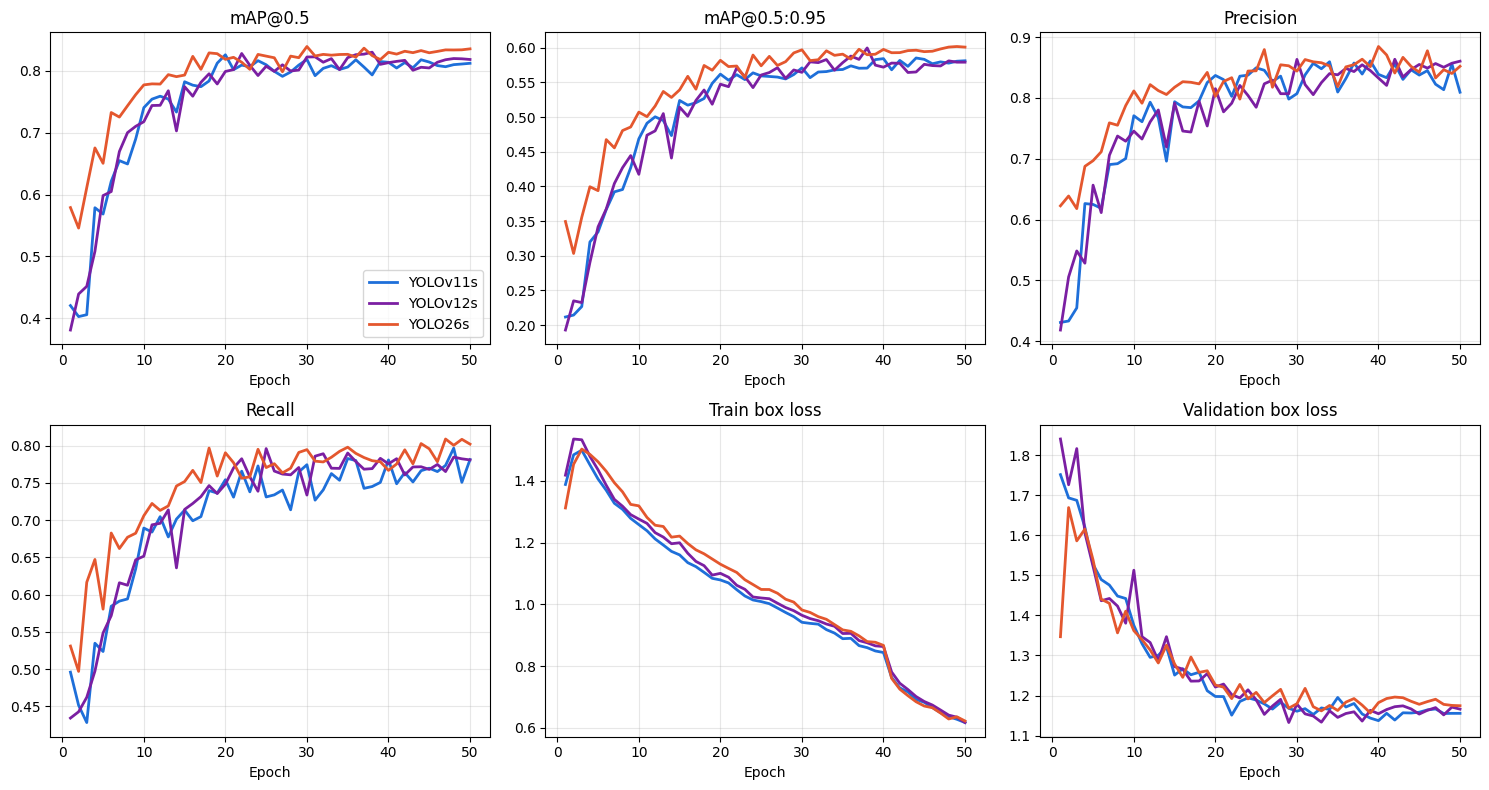

In [7]:
# 6) Side-by-side training curves of the three models (300 dpi, ready for the paper)
import matplotlib.pyplot as plt
COL = {'YOLOv11s': '#1E6FD9', 'YOLOv12s': '#7B1FA2', 'YOLO26s': '#E4572E'}
PANELS = [('metrics/mAP50(B)', 'mAP@0.5'), ('metrics/mAP50-95(B)', 'mAP@0.5:0.95'),
          ('metrics/precision(B)', 'Precision'), ('metrics/recall(B)', 'Recall'),
          ('train/box_loss', 'Train box loss'), ('val/box_loss', 'Validation box loss')]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.ravel(), PANELS):
    for key in MODELS:
        df = pd.read_csv(RUNS / key / 'results.csv')
        df.columns = [c.strip() for c in df.columns]
        if col in df:
            ax.plot(df['epoch'], df[col], label=key, color=COL[key], lw=2)
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(WORK / 'training_curves_comparison.png', dpi=300)
plt.show()

In [8]:
# 7) Collect everything into one zip: all YOLO curves, confusion matrices, results.csv, tables, metadata
OUT = WORK / 'paper_curves'
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir()
for d in RUNS.iterdir():
    if d.is_dir():
        shutil.copytree(d, OUT / d.name, ignore=shutil.ignore_patterns('weights'))
for f in ['table3_split_stats.csv', 'metadata.csv', 'metadata_table7_sample.csv', 'table7_sample_objects.csv',
          'table7_latex.tex', 'class_distribution.csv', 'model_comparison.csv', 'per_class_results.csv',
          'training_curves_comparison.png']:
    if (WORK / f).exists():
        shutil.copy(WORK / f, OUT / f)
shutil.make_archive(str(WORK / 'PolyNex_results'), 'zip', OUT)
print('Saved:', WORK / 'PolyNex_results.zip')
for d in sorted(OUT.iterdir()):
    if d.is_dir():
        print(d.name, '->', sorted(p.name for p in d.glob('*.png')))
print('Trained weights stay in', RUNS, '(runs/<model>/weights/best.pt)')

Saved: /kaggle/working/PolyNex_results.zip
YOLO26s -> ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'results.png']
YOLO26s_test -> ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png']
YOLO26s_val -> ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png']
YOLOv11s -> ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'results.png']
YOLOv11s_test -> ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png']
YOLOv11s_val -> ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png']
YOLOv12s -> ['BoxF1_curve.png', 'Box